# Effective-mass (m*) calibration of the SPB baseline

**Input:** `seebeck_features_clean.csv` from the preprocessing notebook (or `seebeck_features.zip`).

**What this notebook does**
1. Fits **one m* per composition family**: the value that makes S_SPB(n, T; m*) match the measured \|S\| best
   (mean absolute error in µV/K, each sample weighted equally)
2. Does this **inside cross-validation split by paper**: m* is fitted on the training papers only and applied to the test papers.
   The test papers' S is never used, so there's no circularity.
3. Tests two situations:
   - **new paper, known family:** m* comes from other papers of the same family
   - **new family:** m* is fitted on all *other* families (one overall value)
4. Saves the **fold assignments** and the calibrated baseline and residual for each fold, so the PySR/XGBoost notebook
   uses exactly the same splits.

**Interpretation:** the fitted m* is a *calibration constant* of a single-band model. It also absorbs scattering,
multiband and non-parabolic effects, so don't report it as the true band mass.

Physics (SPB, acoustic-phonon scattering, Hall factor 1):
n = 4π(2 m* k_B T / h²)^{3/2} F_{1/2}(η), \|S\| = (k_B/e)[2F₁(η)/F₀(η) − η]

## 0. Settings

In [1]:
INPUT = "seebeck_features_clean.csv"   # or "seebeck_features.zip"; you'll be asked to upload if missing
OUT_DIR = "mstar_calibration"
N_FOLDS = 5                 # GroupKFold on papers (SID)
MIN_TRAIN_PAPERS = 3        # a family needs >= this many TRAINING papers to get its own m*; else use the overall m*
M_BOUNDS = (0.05, 20.0)     # search range for m* (units of electron mass)
LOSS = "abs"                # "abs": mean |S - S_SPB| in uV/K (recommended); "rel": mean |log(S/S_SPB)|
SEED = 42

In [2]:
import json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import expit
from scipy.optimize import minimize_scalar
from sklearn.model_selection import GroupKFold
pd.set_option("display.width", 200)
OUT = Path(OUT_DIR); OUT.mkdir(exist_ok=True)

## 1. Load

In [3]:
p = Path(INPUT)
if not p.exists():
    try:
        from google.colab import files
        p = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(INPUT)
if p.suffix == ".zip":
    with zipfile.ZipFile(p) as z:
        z.extract("seebeck_features_clean.csv", "."); p = Path("seebeck_features_clean.csv")
d = pd.read_csv(p)
d["n_m3"] = 10 ** d["log10_n_cm3"] * 1e6
print(d.shape, "|", d.sample_key.nunique(), "samples |", d.SID.nunique(), "papers")
display(d.groupby("comp_system").agg(points=("point_id", "size"), samples=("sample_key", "nunique"),
        papers=("SID", "nunique")).sort_values("papers", ascending=False))

Saving seebeck_features.zip to seebeck_features.zip
(8358, 25) | 982 samples | 263 papers


,points,samples,papers
comp_system,,,
Other,4455,496,152
Bi-Sb-Te-Se,1740,156,39
Pb chalcogenide,431,66,20
Sn chalcogenide,289,49,15
Half-Heusler-compatible 1:1:1,244,43,12
Cu/Ag chalcogenide,355,38,11
Ge-Te,230,30,10
Skutterudite-compatible TM-Pn 1:3,208,22,6
Sr-Ti-O,53,17,5


## 2. SPB function (same as the preprocessing notebook)

In [4]:
KB, H_PL, M_E, E_CH = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19
_eta = np.linspace(-30, 100, 2601)
_F = lambda j, e: quad(lambda x: x**j * expit(e - x), 0, max(e, 0) + 60, limit=200)[0]
_F12 = np.array([_F(0.5, e) for e in _eta]); _F1 = np.array([_F(1.0, e) for e in _eta]); _F0 = np.logaddexp(0, _eta)

def spb_seebeck_abs_uVK(n_m3, T_K, m_star=1.0):
    """|S_SPB| in uV/K from n (m^-3), T (K) and m* (m_e). Degenerate / non-degenerate limits handled analytically."""
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        F12 = n_m3 / (4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL**2) ** 1.5)
        eta = np.interp(np.log(F12), np.log(_F12), _eta)
        lo, hi = F12 < _F12[0], F12 > _F12[-1]
        eta = np.where(lo, np.log(F12 * 2 / np.sqrt(np.pi)), eta)
        e_hi = (1.5 * F12) ** (2 / 3); e_hi = (1.5 * F12 / (1 + np.pi**2 / (8 * e_hi**2))) ** (2 / 3)
        eta = np.where(hi, e_hi, eta)
        S = np.where(lo, 2 - eta, np.where(hi, np.pi**2 / (3 * eta),
                     2 * np.interp(eta, _eta, _F1) / np.interp(eta, _eta, _F0) - eta))
    return S * KB / E_CH * 1e6

# check: must reproduce the stored m* = 1 column
print("max |diff| vs stored S_SPB (m*=1):",
      float(np.abs(spb_seebeck_abs_uVK(d.n_m3, d.T_K, 1.0) - d.S_SPB_abs_m1_uVK).max()), "uV/K")

max |diff| vs stored S_SPB (m*=1): 1.8758328224066645e-12 uV/K


## 3. The m* fit
For a group of points: choose m* in `M_BOUNDS` that minimizes the weighted mean error between measured \|S\| and
S_SPB(n, T; m*). Weights are 1/(points in that sample), so every **sample** counts equally, however long its curve.
It's a one-dimensional bounded search over log m*.

In [5]:
def fit_mstar(g: pd.DataFrame) -> float:
    w = 1.0 / g.groupby("sample_key")["sample_key"].transform("size").to_numpy()
    S, n, T = g["S_abs_uVK"].to_numpy(), g["n_m3"].to_numpy(), g["T_K"].to_numpy()
    def loss(log_m):
        s = spb_seebeck_abs_uVK(n, T, np.exp(log_m))
        r = np.abs(S - s) if LOSS == "abs" else np.abs(np.log(S / s))
        return np.sum(w * r) / w.sum()
    res = minimize_scalar(loss, bounds=np.log(M_BOUNDS), method="bounded", options={"xatol": 1e-4})
    return float(np.exp(res.x))

def fit_family_mstar(train: pd.DataFrame) -> tuple[dict, float]:
    """m* per family (only families with >= MIN_TRAIN_PAPERS training papers) + overall m*."""
    m_global = fit_mstar(train)
    fam = {f: fit_mstar(g) for f, g in train.groupby("comp_system") if g["SID"].nunique() >= MIN_TRAIN_PAPERS}
    return fam, m_global

def apply_mstar(test: pd.DataFrame, fam: dict, m_global: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    m = test["comp_system"].map(fam).fillna(m_global).to_numpy()
    src = np.where(test["comp_system"].isin(fam), "family", "global")
    return spb_seebeck_abs_uVK(test["n_m3"], test["T_K"], m), m, src

def mae(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 4. Descriptive fit on ALL data (for understanding only, **not** an evaluation)
This uses every paper, so its errors are optimistic. It shows what m* each family "wants" and how much a
single-band model can explain at best. Evaluation is in section 5.

In [6]:
fam_all, glob_all = fit_family_mstar(d)
rows = []
for f, g in d.groupby("comp_system"):
    m_f = fam_all.get(f, glob_all)
    rows.append({"family": f, "papers": g.SID.nunique(), "samples": g.sample_key.nunique(), "m*_fitted": round(m_f, 3),
                 "MAE_m1": round(mae(g.S_abs_uVK, g.S_SPB_abs_m1_uVK), 1),
                 "MAE_fitted": round(mae(g.S_abs_uVK, spb_seebeck_abs_uVK(g.n_m3, g.T_K, m_f)), 1)})
desc = pd.DataFrame(rows).sort_values("papers", ascending=False)
print(f"overall m* (all families pooled): {glob_all:.3f}")
display(desc)

overall m* (all families pooled): 0.797


,family,papers,samples,m*_fitted,MAE_m1,MAE_fitted
6,Other,152,496,0.726,87.5,83.9
0,Bi-Sb-Te-Se,39,156,1.019,59.5,59.7
7,Pb chalcogenide,20,66,0.416,92.0,45.6
10,Sn chalcogenide,15,49,0.963,52.4,52.6
3,Half-Heusler-compatible 1:1:1,12,43,0.412,94.8,76.0
1,Cu/Ag chalcogenide,11,38,0.165,153.3,47.9
2,Ge-Te,10,30,2.651,88.7,45.7
9,Skutterudite-compatible TM-Pn 1:3,6,22,1.744,64.1,75.5
11,Sr-Ti-O,5,17,6.096,145.5,35.7
12,Zn-O,5,20,0.343,89.7,58.9


### Pisarenko plots (points near 300 K, with the SPB curve at 300 K for the fitted m*)

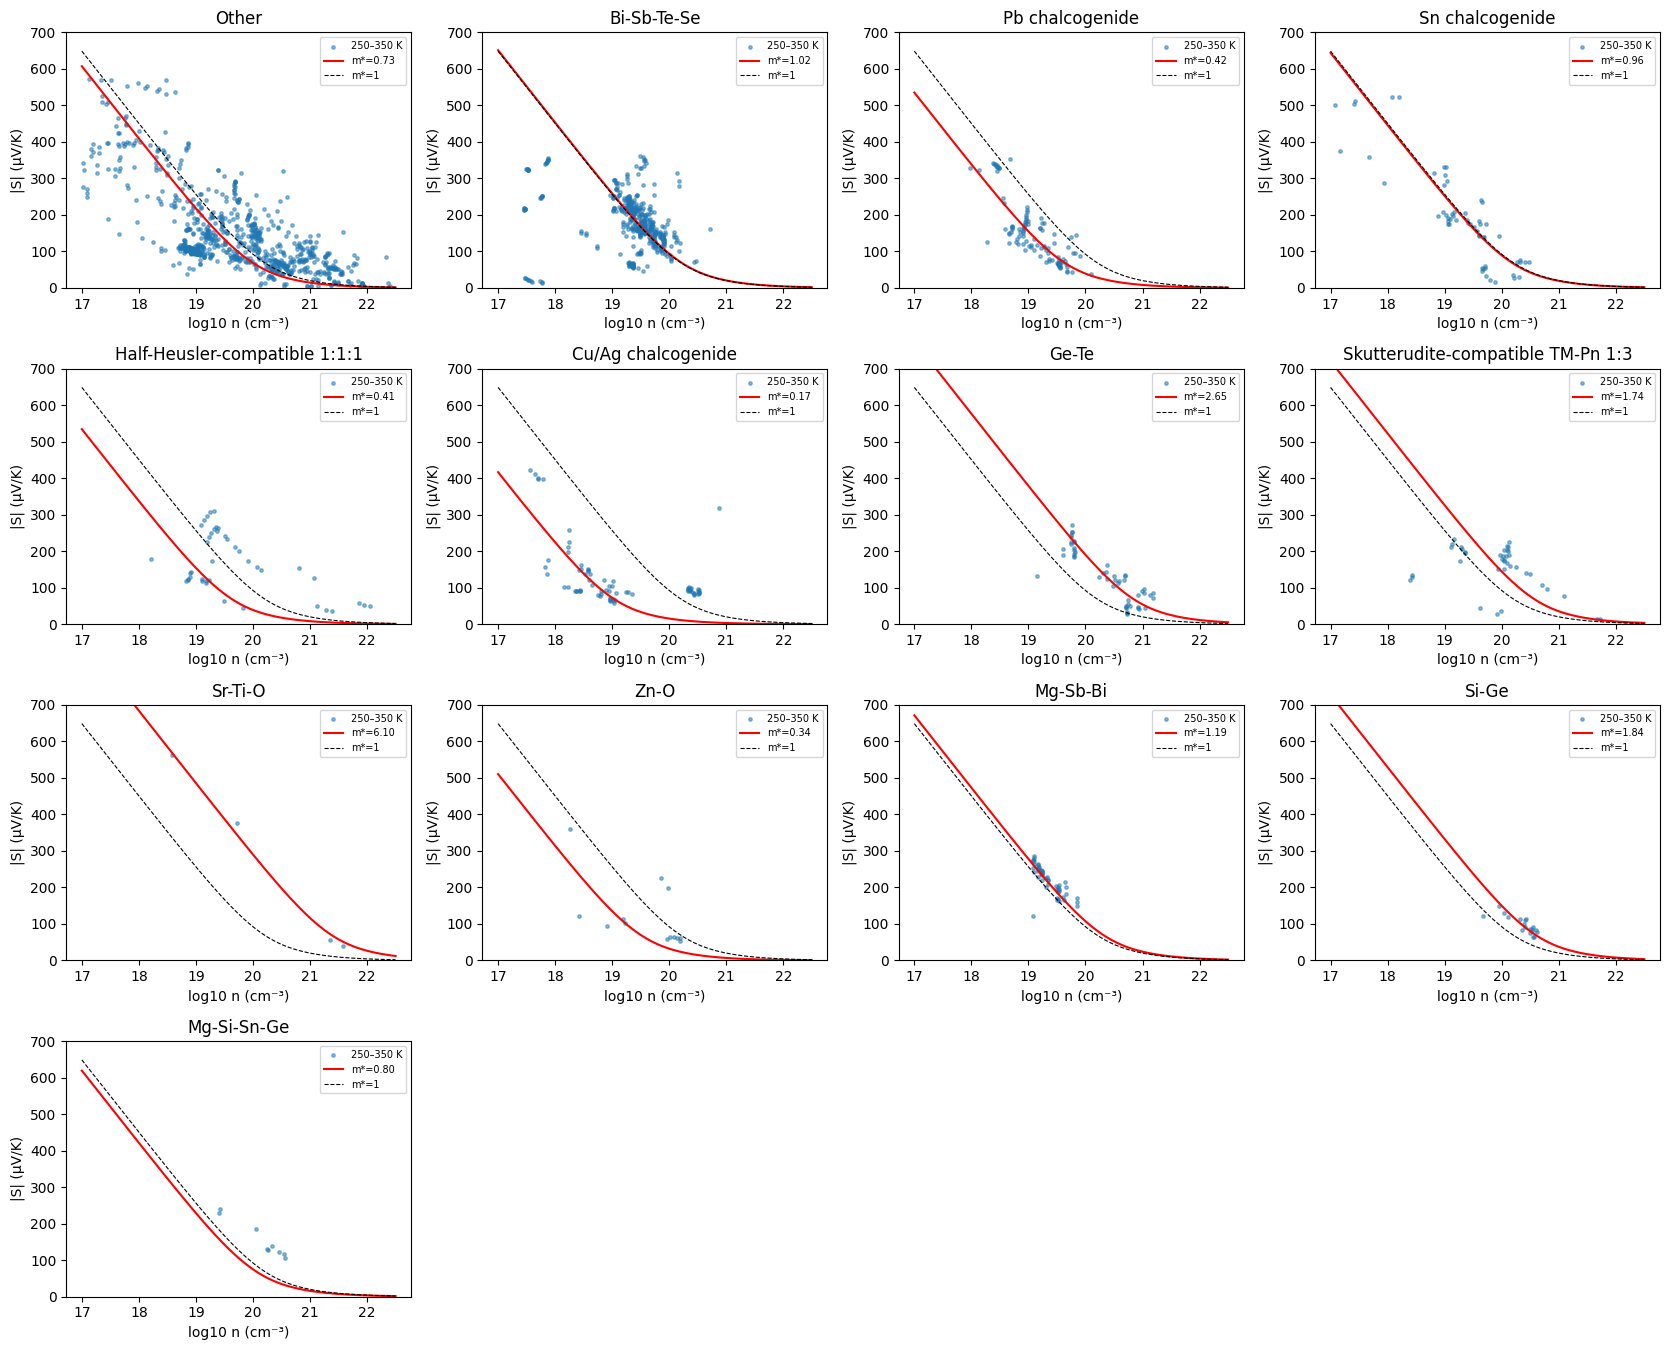

In [7]:
fams = desc.family.tolist()
nc = 4; nr = int(np.ceil(len(fams) / nc))
fig, ax = plt.subplots(nr, nc, figsize=(4.2 * nc, 3.4 * nr)); ax = ax.ravel()
ngrid = np.logspace(17, 22.5, 200)
for a, f in zip(ax, fams):
    g = d[(d.comp_system == f) & d.T_K.between(250, 350)]
    a.scatter(g.log10_n_cm3, g.S_abs_uVK, s=6, alpha=.5, label="250–350 K")
    m_f = fam_all.get(f, glob_all)
    a.plot(np.log10(ngrid), spb_seebeck_abs_uVK(ngrid * 1e6, 300, m_f), "r", label=f"m*={m_f:.2f}")
    a.plot(np.log10(ngrid), spb_seebeck_abs_uVK(ngrid * 1e6, 300, 1.0), "k--", lw=.8, label="m*=1")
    a.set(title=f, xlabel="log10 n (cm⁻³)", ylabel="|S| (µV/K)", ylim=(0, 700)); a.legend(fontsize=7)
for a in ax[len(fams):]: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Cross-validated calibration (the real evaluation)
`GroupKFold` on papers: each paper sits entirely in one test fold. In each fold:
fit m* on the training papers → compute S_SPB for the test papers → score against their measured \|S\|.
The fold assignment is saved and **must be reused** by the modelling notebook.

In [8]:
gkf = GroupKFold(n_splits=N_FOLDS)
d["fold"] = -1
oof_S = np.full(len(d), np.nan); oof_m = np.full(len(d), np.nan); oof_src = np.empty(len(d), dtype=object)
fold_m = []
# shuffle papers reproducibly before grouping so folds aren't ordered by SID
rng = np.random.default_rng(SEED)
sid_perm = {s: i for i, s in enumerate(rng.permutation(d.SID.unique()))}
groups = d.SID.map(sid_perm)
for k, (tr, te) in enumerate(gkf.split(d, groups=groups)):
    train, test = d.iloc[tr], d.iloc[te]
    fam, m_g = fit_family_mstar(train)
    s, m, src = apply_mstar(test, fam, m_g)
    oof_S[te], oof_m[te], oof_src[te] = s, m, src
    d.iloc[te, d.columns.get_loc("fold")] = k
    fold_m.append({"fold": k, "global": m_g, **fam})
d["mstar_cv"] = oof_m; d["mstar_source"] = oof_src
d["S_SPB_cal_uVK"] = oof_S
d["dS_cal_uVK"] = d["S_abs_uVK"] - d["S_SPB_cal_uVK"]     # residual target for PySR (per fold)
fold_m = pd.DataFrame(fold_m).set_index("fold")

def score_table(df):
    out = []
    for f, g in [("ALL", df)] + list(df.groupby("comp_system")):
        out.append({"family": f, "papers": g.SID.nunique(), "points": len(g),
                    "MAE_m1": mae(g.S_abs_uVK, g.S_SPB_abs_m1_uVK), "MAE_cal": mae(g.S_abs_uVK, g.S_SPB_cal_uVK),
                    "RMSE_m1": rmse(g.S_abs_uVK, g.S_SPB_abs_m1_uVK), "RMSE_cal": rmse(g.S_abs_uVK, g.S_SPB_cal_uVK),
                    "share_global_m*": float((g.mstar_source == "global").mean())})
    t = pd.DataFrame(out).round(2)
    return pd.concat([t[t.family == "ALL"], t[t.family != "ALL"].sort_values("papers", ascending=False)])
cv_scores = score_table(d)
print("Out-of-fold scores (test papers only), uV/K:"); display(cv_scores)

Out-of-fold scores (test papers only), uV/K:


,family,papers,points,MAE_m1,MAE_cal,RMSE_m1,RMSE_cal,share_global_m*
0,ALL,263,8358,82.02,75.60,125.90,119.21,0.03
7,Other,152,4455,87.51,84.87,138.85,134.96,0.00
1,Bi-Sb-Te-Se,39,1740,59.51,60.93,103.81,105.93,0.00
8,Pb chalcogenide,20,431,91.97,46.19,105.81,61.09,0.00
11,Sn chalcogenide,15,289,52.43,61.38,64.75,74.61,0.00
4,Half-Heusler-compatible 1:1:1,12,244,94.83,118.75,110.89,146.47,0.00
2,Cu/Ag chalcogenide,11,355,153.33,62.32,182.63,76.57,0.00
3,Ge-Te,10,230,88.71,57.05,101.27,77.24,0.00
10,Skutterudite-compatible TM-Pn 1:3,6,208,64.07,116.00,86.03,143.82,0.00
12,Sr-Ti-O,5,53,145.46,73.96,160.33,83.05,0.00


### How stable is m* across folds?
If a family's m* moves a lot between folds, its calibration depends on which papers are included,
so treat that family's results with caution.

,mean,std,min,max,cv_%
Mg-Sb-Bi,1.203,0.016,1.192,1.225,1.321
Bi-Sb-Te-Se,1.022,0.028,0.999,1.072,2.771
Pb chalcogenide,0.416,0.013,0.402,0.433,3.026
global,0.799,0.028,0.758,0.832,3.452
Si-Ge,1.898,0.093,1.837,2.034,4.903
Other,0.731,0.054,0.670,0.819,7.421
Zn-O,0.326,0.034,0.274,0.343,10.491
Sn chalcogenide,0.949,0.123,0.733,1.025,12.959
Ge-Te,2.873,0.524,2.519,3.785,18.229
Cu/Ag chalcogenide,0.153,0.036,0.095,0.187,23.259


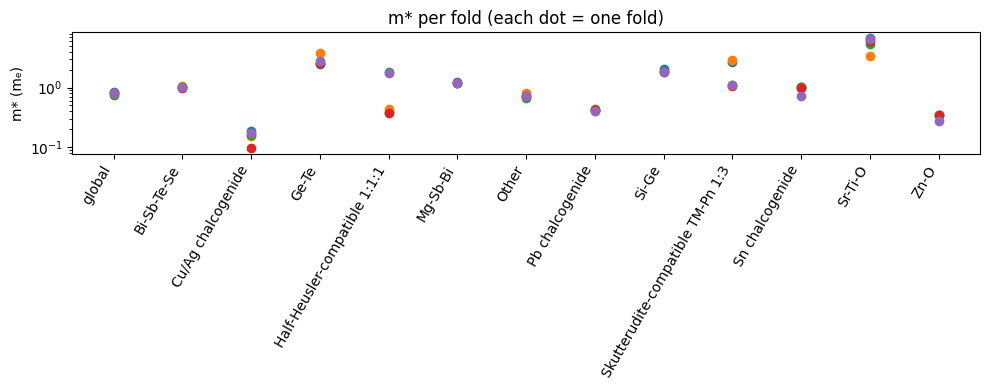

In [9]:
stab = fold_m.agg(["mean", "std", "min", "max"]).T
stab["cv_%"] = 100 * stab["std"] / stab["mean"]
display(stab.round(3).sort_values("cv_%"))
fold_m.T.plot(marker="o", ls="none", figsize=(10, 4), legend=False, logy=True, title="m* per fold (each dot = one fold)")
plt.xticks(range(len(fold_m.columns)), fold_m.columns, rotation=60, ha="right"); plt.ylabel("m* (mₑ)")
plt.tight_layout(); plt.show()

## 6. New-family test (leave one family out)
For each family: fit a single m* on **all other families** and predict this family.
This is the honest baseline for a claim about *unseen families*.

In [10]:
lofo = []
for f, g in d.groupby("comp_system"):
    m_other = fit_mstar(d[d.comp_system != f])
    s = spb_seebeck_abs_uVK(g.n_m3, g.T_K, m_other)
    lofo.append({"family": f, "papers": g.SID.nunique(), "m*_from_other_families": round(m_other, 3),
                 "MAE_m1": round(mae(g.S_abs_uVK, g.S_SPB_abs_m1_uVK), 1), "MAE_new_family": round(mae(g.S_abs_uVK, s), 1),
                 "MAE_known_family_cv": round(mae(g.S_abs_uVK, g.S_SPB_cal_uVK), 1)})
lofo = pd.DataFrame(lofo).sort_values("papers", ascending=False)
display(lofo)

,family,papers,m*_from_other_families,MAE_m1,MAE_new_family,MAE_known_family_cv
6,Other,152,0.869,87.5,85.4,84.9
0,Bi-Sb-Te-Se,39,0.664,59.5,67.5,60.9
7,Pb chalcogenide,20,0.884,92.0,79.7,46.2
10,Sn chalcogenide,15,0.775,52.4,56.5,61.4
3,Half-Heusler-compatible 1:1:1,12,0.800,94.8,89.3,118.8
1,Cu/Ag chalcogenide,11,0.843,153.3,140.9,62.3
2,Ge-Te,10,0.778,88.7,98.5,57.1
9,Skutterudite-compatible TM-Pn 1:3,6,0.791,64.1,63.9,116.0
11,Sr-Ti-O,5,0.779,145.5,158.8,74.0
12,Zn-O,5,0.828,89.7,78.8,69.7


## 7. Plots: before vs after calibration (out-of-fold)

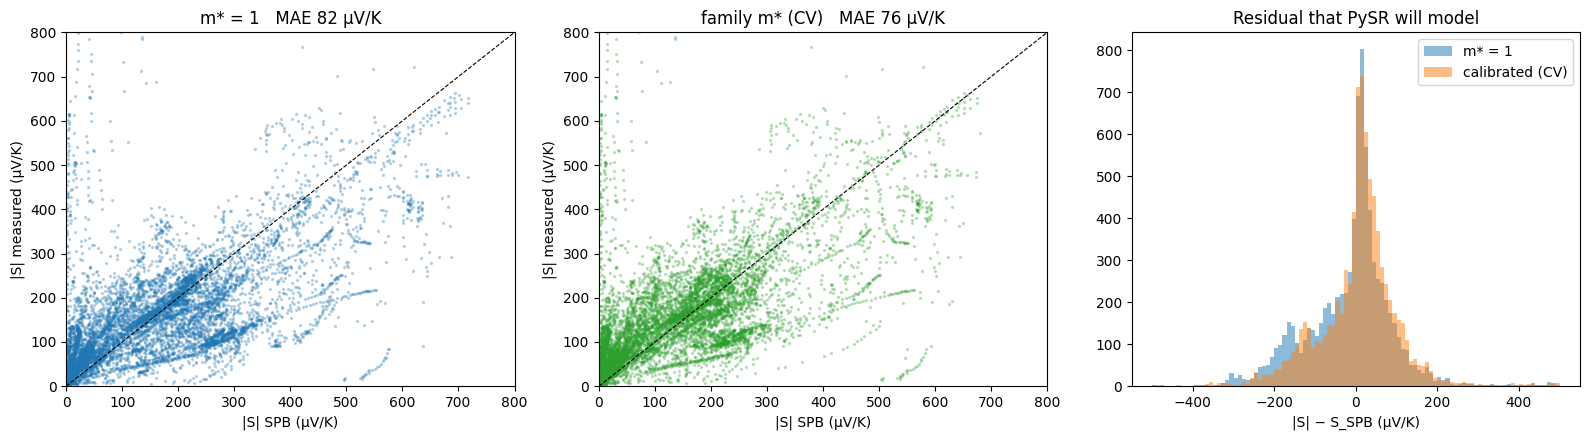

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
lim = [0, 800]
ax[0].scatter(d.S_SPB_abs_m1_uVK, d.S_abs_uVK, s=2, alpha=.25); ax[0].set_title(f"m* = 1   MAE {mae(d.S_abs_uVK, d.S_SPB_abs_m1_uVK):.0f} µV/K")
ax[1].scatter(d.S_SPB_cal_uVK, d.S_abs_uVK, s=2, alpha=.25, c="C2"); ax[1].set_title(f"family m* (CV)   MAE {mae(d.S_abs_uVK, d.S_SPB_cal_uVK):.0f} µV/K")
for a in ax[:2]:
    a.plot(lim, lim, "k--", lw=.8); a.set(xlim=lim, ylim=lim, xlabel="|S| SPB (µV/K)", ylabel="|S| measured (µV/K)")
ax[2].hist(d.S_abs_uVK - d.S_SPB_abs_m1_uVK, bins=100, range=(-500, 500), alpha=.5, label="m* = 1")
ax[2].hist(d.dS_cal_uVK, bins=100, range=(-500, 500), alpha=.5, label="calibrated (CV)")
ax[2].set(xlabel="|S| − S_SPB (µV/K)", title="Residual that PySR will model"); ax[2].legend()
plt.tight_layout(); plt.show()

## 8. Save
- `features_with_folds.csv`: the clean features plus `fold`, `mstar_cv`, `mstar_source`, `S_SPB_cal_uVK`, `dS_cal_uVK`.
  **Use this file for XGBoost and PySR**, keep the same `fold` column, and refit m* inside any new split you make.
- `mstar_by_fold.csv`, `cv_scores.csv`, `new_family_scores.csv`, `mstar_descriptive_alldata.csv`, `mstar_report.json`

In [12]:
d.drop(columns=["n_m3"]).to_csv(OUT / "features_with_folds.csv", index=False)
fold_m.to_csv(OUT / "mstar_by_fold.csv")
cv_scores.to_csv(OUT / "cv_scores.csv", index=False)
lofo.to_csv(OUT / "new_family_scores.csv", index=False)
desc.to_csv(OUT / "mstar_descriptive_alldata.csv", index=False)
report = {"settings": {"N_FOLDS": N_FOLDS, "MIN_TRAIN_PAPERS": MIN_TRAIN_PAPERS, "M_BOUNDS": M_BOUNDS,
                       "LOSS": LOSS, "SEED": SEED, "weighting": "equal weight per sample"},
          "overall_cv": cv_scores[cv_scores.family == "ALL"].iloc[0].to_dict(),
          "mstar_alldata_descriptive": {"global": glob_all, **fam_all}}
(OUT / "mstar_report.json").write_text(json.dumps(report, indent=2, default=float))
print(json.dumps(report["overall_cv"], indent=2, default=float))

{
  "family": "ALL",
  "papers": 263,
  "points": 8358,
  "MAE_m1": 82.02,
  "MAE_cal": 75.6,
  "RMSE_m1": 125.9,
  "RMSE_cal": 119.21,
  "share_global_m*": 0.03
}


In [13]:
import shutil
shutil.make_archive("mstar_calibration", "zip", OUT)
try:
    from google.colab import files
    files.download("mstar_calibration.zip")
except ImportError:
    print("zip at mstar_calibration.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>